# Exploratory analysis: monthly demand

Data: [Kaggle Store Item Demand Forecasting](https://www.kaggle.com/competitions/demand-forecasting-kernels-only/data), daily sales for 50 items across 10 stores, 2013–2017. Summed over stores to monthly sales per item, the same way `forecast.py` does.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import forecast as f

y = f.load('../data/train.csv')
print(y.shape, 'months x items')
y.iloc[:5, :8]

(60, 50) months x items


item,1,2,3,4,5,6,7,8
date,,,,,,,,
2013-01-01,3794,10379,6345,3718,3103,10014,10151,13509
2013-02-01,3863,10338,6529,3920,3220,10401,10241,13478
2013-03-01,5190,13933,8546,5246,4307,13836,13957,18201
2013-04-01,5783,14938,9704,5834,4729,15250,15434,20078
2013-05-01,6298,17179,10755,6439,5392,16931,17179,22419


## 1. Trend and seasonality
Total demand peaks every July and bottoms out every January. The trend is upward, but growth is slowing.

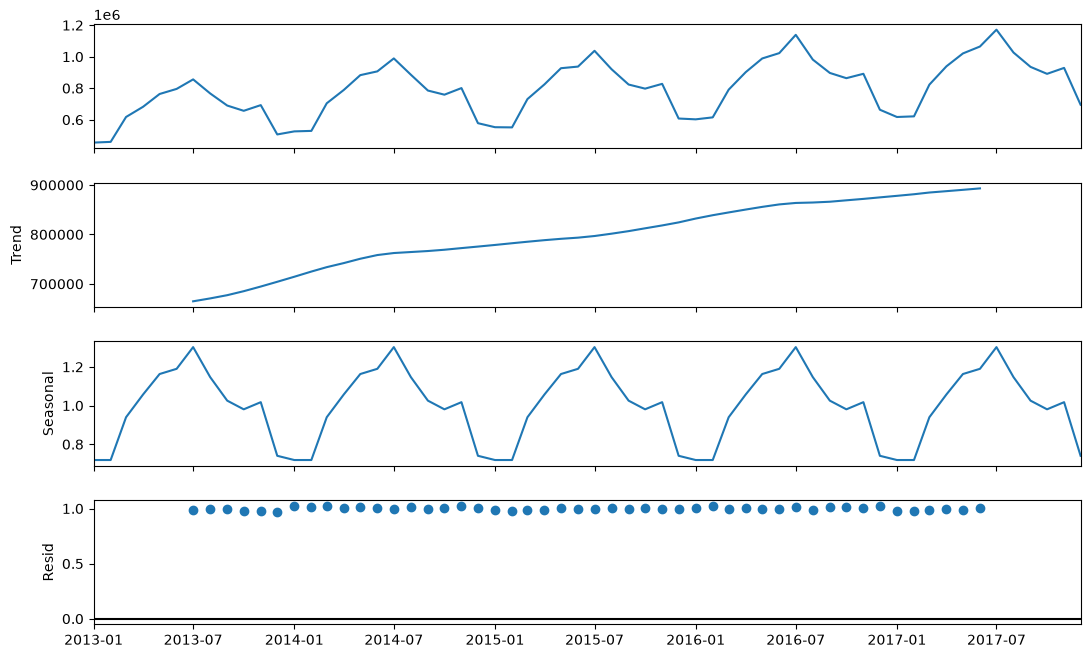

In [2]:
total = y.sum(axis=1)
seasonal_decompose(total, model='multiplicative', period=12).plot().set_size_inches(12, 7)

In [3]:
growth = total.groupby(total.index.year).sum().pct_change().mul(100).round(1)
growth.rename('YoY growth %').to_frame().T

date,2013,2014,2015,2016,2017
YoY growth %,NaN,15.0,4.4,8.6,3.6


## 2. Do items share the same seasonal shape?
Each item's monthly profile, divided by its own yearly average. If the lines overlap, one pooled model can learn the seasonality for every item at once. This is why `forecast.py` trains a single XGBoost model on scale-free ratios instead of 50 separate models.

max spread between items in any month: 0.028


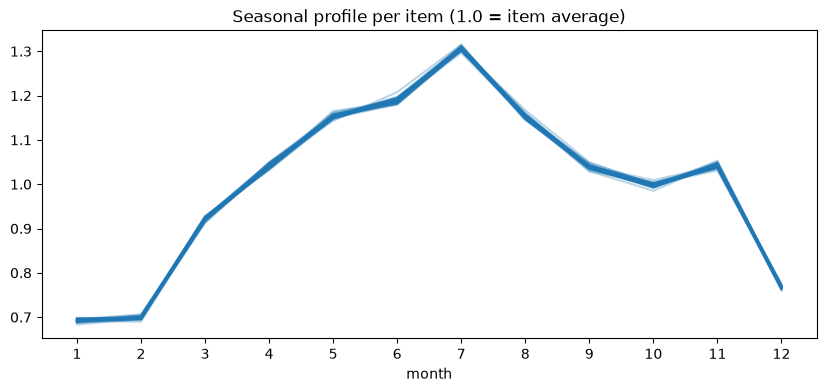

In [4]:
profile = y.groupby(y.index.month).mean()
profile = profile / profile.mean()
ax = profile.plot(legend=False, alpha=0.3, color='tab:blue', figsize=(10, 4), title='Seasonal profile per item (1.0 = item average)')
ax.set_xlabel('month'); ax.set_xticks(range(1, 13))
print('max spread between items in any month:', round((profile.max(axis=1) - profile.min(axis=1)).max(), 3))

## 3. Backtest results (from `python forecast.py`)
MAPE % averaged over 50 items, for each 6-month test window.

In [5]:
bt = pd.read_csv('../results/backtest.csv')
bt.pivot_table(index='model', columns='test_start', values='mape').round(2)

test_start,2016-07-01,2017-01-01,2017-07-01
model,,,
prophet,2.25,4.92,1.81
sarima,1.34,5.72,1.06
seasonal_naive,7.73,3.15,3.80
xgboost,2.85,3.85,1.70


The Jan–Jun 2017 window is the odd one out. Every model gets worse, and the naive baseline wins. Year-on-year growth fell from 8.6% in 2016 to 3.6% in 2017 (table in section 1). The models carried 2016's growth forward; SARIMA over-forecast every month of that window by 4–7%. The baseline assumes no growth, so it happened to land closer. A model trained on history can't anticipate a change in growth rate; in production this is what forecast monitoring and re-training are for.

## 4. Does the average hide inconsistent wins?

Each model has 150 item/window errors: 50 items across three test windows. Compare each with the seasonal baseline on the same item and window. A positive difference means lower error than the baseline; the win rate counts how often that happens.

The paired rows share products and dates, so they are not 150 independent experiments. The spread below describes these backtests, not a confidence interval for future performance.

In [6]:
paired = bt.pivot(index=['test_start', 'item'], columns='model', values='mape')
assert paired.shape == (150, 4) and paired.notna().all().all()
model_names = ['sarima', 'prophet', 'xgboost']
gains = paired[model_names].rsub(paired['seasonal_naive'], axis=0)
rows = []
for window, errors in paired.groupby(level='test_start'):
    for name in model_names:
        rows.append({
            'test_start': window,
            'model': name,
            'items': len(errors),
            'items_beating_baseline': int((errors[name] < errors.seasonal_naive).sum()),
            'mean_mape': errors[name].mean(),
            'baseline_mape': errors.seasonal_naive.mean(),
            'mean_improvement_pp': (errors.seasonal_naive - errors[name]).mean(),
        })
consistency = pd.DataFrame(rows)
consistency['win_rate_pct'] = consistency.items_beating_baseline / consistency['items'] * 100
assert consistency['items'].eq(50).all()
assert consistency.items_beating_baseline.between(0, 50).all()
consistency.to_csv('../results/model_consistency.csv', index=False)
display(consistency.round(2))
print('Positive values mean lower MAPE than the baseline, in percentage points:')
gains.agg(['mean', 'median', 'min', 'max']).round(2)

,test_start,model,items,items_beating_baseline,mean_mape,baseline_mape,mean_improvement_pp,win_rate_pct
0,2016-07-01,sarima,50,50,1.34,7.73,6.39,100.0
1,2016-07-01,prophet,50,50,2.25,7.73,5.48,100.0
2,2016-07-01,xgboost,50,50,2.85,7.73,4.89,100.0
3,2017-01-01,sarima,50,2,5.72,3.15,-2.57,4.0
4,2017-01-01,prophet,50,2,4.92,3.15,-1.77,4.0
5,2017-01-01,xgboost,50,14,3.85,3.15,-0.70,28.0
6,2017-07-01,sarima,50,50,1.06,3.80,2.74,100.0
7,2017-07-01,prophet,50,50,1.81,3.80,1.99,100.0
8,2017-07-01,xgboost,50,50,1.70,3.80,2.10,100.0


Positive values mean lower MAPE than the baseline, in percentage points:


model,sarima,prophet,xgboost
mean,2.19,1.90,2.10
median,2.86,2.05,2.21
min,-5.41,-3.81,-3.40
max,7.76,6.66,6.79


## 5. Inspect a fixed product through the bad window

Item 1 is a fixed example, rather than an average across products. Refit SARIMA at each of the same three origins and compare its six monthly predictions with actual demand. The signed error shows direction: positive means over-forecasting. The per-window MAPE must match the saved backtest, which also checks that this diagnostic uses the same training boundary.

,mape,mean_signed_error_pct
test_start,,
2016-07-01,2.58,0.71
2017-01-01,5.72,5.72
2017-07-01,1.50,-1.32


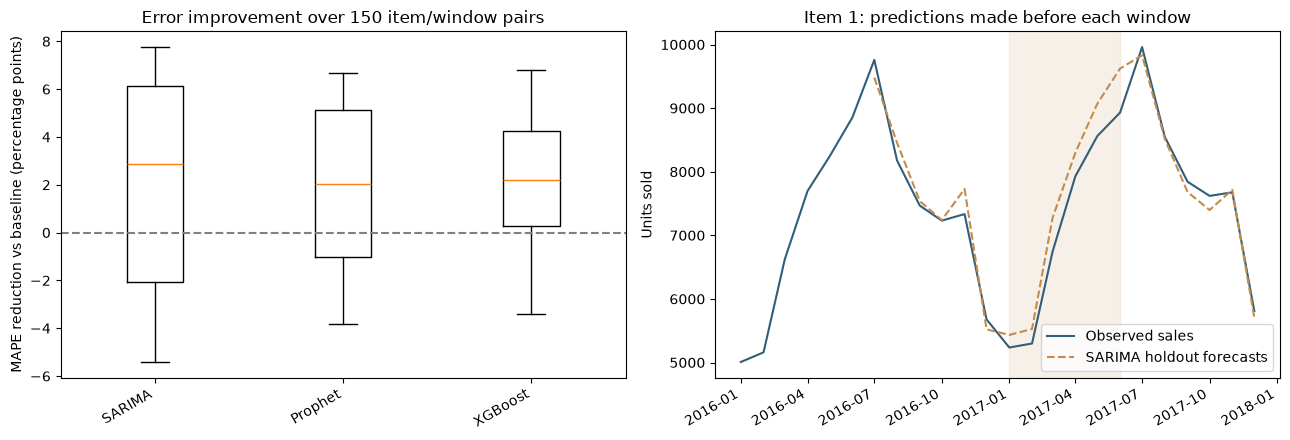

In [7]:
import numpy as np

item = 1
rows = []
for k in range(f.FOLDS, 0, -1):
    origin = len(y) - k * f.H
    history = y.iloc[:origin][[item]]
    actual = y.iloc[origin:origin + f.H][item]
    prediction = f.sarima(history)[item]
    assert prediction.index.equals(actual.index)
    expected = bt.loc[(bt.model == 'sarima') & (bt.item == item)
                      & (bt.test_start == str(actual.index[0].date())), 'mape'].iloc[0]
    assert np.isclose(f.mape(actual, prediction), expected)
    for date in actual.index:
        rows.append({'date': date, 'test_start': str(actual.index[0].date()),
                     'actual': actual.loc[date], 'forecast': prediction.loc[date]})
item_errors = pd.DataFrame(rows).set_index('date')
item_errors['signed_error_pct'] = (item_errors.forecast / item_errors.actual - 1) * 100
item_errors['absolute_error_pct'] = item_errors.signed_error_pct.abs()
assert len(item_errors) == 18 and item_errors.index.is_unique
assert np.isfinite(item_errors.to_numpy()[:, 1:].astype(float)).all()
item_errors.to_csv('../results/item_1_forecast_errors.csv')
display(item_errors.groupby('test_start').agg(
    mape=('absolute_error_pct', 'mean'), mean_signed_error_pct=('signed_error_pct', 'mean')
).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot([gains[name] for name in model_names], tick_labels=['SARIMA', 'Prophet', 'XGBoost'])
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set(ylabel='MAPE reduction vs baseline (percentage points)',
            title='Error improvement over 150 item/window pairs')
axes[1].plot(y.loc['2016':].index, y.loc['2016':, item], color='#315e78', label='Observed sales')
axes[1].plot(item_errors.index, item_errors.forecast, '--', color='#c48b4a', label='SARIMA holdout forecasts')
axes[1].axvspan(pd.Timestamp('2017-01-01'), pd.Timestamp('2017-06-01'), color='#c48b4a', alpha=0.12)
axes[1].set(ylabel='Units sold', title='Item 1: predictions made before each window')
axes[1].legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('../results/forecast_diagnostics.png', dpi=120)

The average model score is useful for choosing a starting point, but it hides a whole period in which the baseline is harder to beat. Inspect signed error as well as MAPE: consistent over-forecasting has a different purchasing implication from errors that alternate around demand. An operating forecast would need fresh error monitoring and stockout/cost information before these results could guide inventory decisions.